# ICT4403 Assignment 2 — Autoregressive Text Generation

**Models:** Simple RNN, Bidirectional RNN, LSTM, GRU  
**Dataset:** *The Time Machine* by H. G. Wells (word-level next-token prediction)

This notebook downloads the public-domain text of H. G. Wells’ *The Time Machine* from Project Gutenberg, removes the Gutenberg header/footer when detectable, preprocesses the text, trains all four models under comparable settings, evaluates them, and compares generated text at temperatures 0.5, 1.0, and 1.5.

> Run all cells from top to bottom. Training time depends on your computer/runtime. The final metrics and generated samples are produced by your run; do not report placeholder or fabricated results.


In [1]:
# %pip install tensorflow pandas numpy matplotlib scikit-learn

import os, time, random, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Download and inspect the dataset


In [2]:
DATA_URL = "https://www.gutenberg.org/cache/epub/35/pg35.txt"
DATA_PATH = "the_time_machine.txt"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8-sig") as f:
    raw_text = f.read()

# Remove Project Gutenberg boilerplate if the standard markers are present.
start_match = re.search(r"\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw_text, flags=re.IGNORECASE | re.DOTALL)
end_match = re.search(r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw_text, flags=re.IGNORECASE | re.DOTALL)
if start_match:
    raw_text = raw_text[start_match.end():]
if end_match:
    raw_text = raw_text[:end_match.start()]

print("Characters:", len(raw_text))
print("Preview:\n", raw_text[:1000])
print("Dataset source:", DATA_URL)


Characters: 180498
Preview:
 




The Time Machine

An Invention

by H. G. Wells


CONTENTS

 I Introduction
 II The Machine
 III The Time Traveller Returns
 IV Time Travelling
 V In the Golden Age
 VI The Sunset of Mankind
 VII A Sudden Shock
 VIII Explanation
 IX The Morlocks
 X When Night Came
 XI The Palace of Green Porcelain
 XII In the Darkness
 XIII The Trap of the White Sphinx
 XIV The Further Vision
 XV The Time Traveller’s Return
 XVI After the Story
 Epilogue




 I.
 Introduction


The Time Traveller (for so it will be convenient to speak of him)
was expounding a recondite matter to us. His grey eyes shone and
twinkled, and his usually pale face was flushed and animated. The
fire burnt brightly, and the soft radiance of the incandescent
lights in the lilies of silver caught the bubbles that flashed and
passed in our glasses. Our chairs, being his patents, embraced and
caressed us rather than submitted to be sat upon, and there was that
luxurious after-dinner atmosphere, whe

## 2. Preprocess text and build next-word sequences


In [3]:
# Normalize whitespace and tokenize into words while preserving punctuation as tokens.
text = raw_text.lower()
tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]", text)
print("Token count:", len(tokens))
print("First 40 tokens:", tokens[:40])

# Limit vocabulary for manageable training. Rare words map to <unk>.
from collections import Counter
MAX_VOCAB = 12000
counts = Counter(tokens)
special = ["<pad>", "<unk>"]
vocab_words = special + [w for w, _ in counts.most_common(MAX_VOCAB - len(special)) if w not in special]
word_to_id = {w:i for i,w in enumerate(vocab_words)}
id_to_word = {i:w for w,i in word_to_id.items()}
token_ids = np.array([word_to_id.get(w, word_to_id["<unk>"]) for w in tokens], dtype=np.int32)

# Chronological split avoids placing later text in training.
split = int(0.90 * len(token_ids))
train_ids, val_ids = token_ids[:split], token_ids[split:]

SEQ_LEN = 20
STRIDE = 3

def make_sequences(ids, seq_len=SEQ_LEN, stride=STRIDE):
    X, y = [], []
    for start in range(0, len(ids) - seq_len, stride):
        X.append(ids[start:start+seq_len])
        y.append(ids[start+seq_len])
    return np.asarray(X, dtype=np.int32), np.asarray(y, dtype=np.int32)

X_train, y_train = make_sequences(train_ids)
X_val, y_val = make_sequences(val_ids)
print("Vocabulary size:", len(vocab_words))
print("Training examples:", X_train.shape, y_train.shape)
print("Validation examples:", X_val.shape, y_val.shape)


Token count: 38464
First 40 tokens: ['the', 'time', 'machine', 'an', 'invention', 'by', 'h', '.', 'g', '.', 'wells', 'contents', 'i', 'introduction', 'ii', 'the', 'machine', 'iii', 'the', 'time', 'traveller', 'returns', 'iv', 'time', 'travelling', 'v', 'in', 'the', 'golden', 'age', 'vi', 'the', 'sunset', 'of', 'mankind', 'vii', 'a', 'sudden', 'shock', 'viii']
Vocabulary size: 4647
Training examples: (11533, 20) (11533,)
Validation examples: (1276, 20) (1276,)


## 3. Define comparable model architectures


In [4]:
EMBED_DIM = 96
HIDDEN_UNITS = 128
BATCH_SIZE = 128
EPOCHS = 8  # Increase if time permits; keep identical for all four models.
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(
    min(len(X_train), 20000), seed=SEED, reshuffle_each_iteration=True
).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

def build_model(kind):
    inp = layers.Input(shape=(SEQ_LEN,), dtype="int32")
    x = layers.Embedding(input_dim=len(vocab_words), output_dim=EMBED_DIM, mask_zero=False)(inp)
    if kind == "Simple RNN":
        x = layers.SimpleRNN(HIDDEN_UNITS)(x)
    elif kind == "Bidirectional RNN":
        x = layers.Bidirectional(layers.SimpleRNN(HIDDEN_UNITS))(x)
    elif kind == "LSTM":
        x = layers.LSTM(HIDDEN_UNITS)(x)
    elif kind == "GRU":
        x = layers.GRU(HIDDEN_UNITS)(x)
    else:
        raise ValueError(kind)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(len(vocab_words), activation="softmax")(x)
    model = models.Model(inp, out, name=kind.replace(" ", "_").lower())
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["sparse_categorical_accuracy"]
    )
    return model

model_kinds = ["Simple RNN", "Bidirectional RNN", "LSTM", "GRU"]


## 4. Train and evaluate all four models


In [5]:
trained_models = {}
histories = {}
results = []

for kind in model_kinds:
    print("\\n" + "="*70 + "\\nTraining:", kind)
    model = build_model(kind)
    start_time = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=2, restore_best_weights=True
            )
        ]
    )
    elapsed = time.time() - start_time
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    perplexity = float(np.exp(min(val_loss, 50)))
    trained_models[kind] = model
    histories[kind] = history
    results.append({
        "Model": kind,
        "Validation Loss": float(val_loss),
        "Perplexity": perplexity,
        "Validation Accuracy": float(val_acc),
        "Training Time (seconds)": elapsed,
        "Epochs Run": len(history.history["loss"])
    })

results_df = pd.DataFrame(results).sort_values("Validation Loss")
display(results_df)
results_df.to_csv("model_comparison_results.csv", index=False)


\n======================================================================\nTraining: Simple RNN
Epoch 1/8
91/91 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: 6.7039 - sparse_categorical_accuracy: 0.0534 - val_loss: 6.1769 - val_sparse_categorical_accuracy: 0.0697
Epoch 2/8
91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 6.1535 - sparse_categorical_accuracy: 0.0568 - val_loss: 6.7520 - val_sparse_categorical_accuracy: 0.0619
Epoch 3/8
91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - loss: 6.0549 - sparse_categorical_accuracy: 0.0656 - val_loss: 6.0635 - val_sparse_categorical_accuracy: 0.1003
Epoch 4/8
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - loss: 5.7620 - sparse_categorical_accuracy: 0.0841 - val_loss: 6.0229 - val_sparse_categorical_accuracy: 0.1003
Epoch 5/8
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - loss: 5.5332 - sparse_categorical_accuracy: 0.1034 - val_loss: 5.9440 - val_sparse_categorical_accuracy: 0.1129
Epoch 6/8
91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - loss: 5.2900 - sparse_categorica

,Model,Validation Loss,Perplexity,Validation Accuracy,Training Time (seconds),Epochs Run
0,Simple RNN,5.896249,363.670884,0.126176,50.168966,8
1,Bidirectional RNN,5.991584,400.047904,0.125392,69.547988,7
3,GRU,6.015560,409.755299,0.136364,77.233221,8
2,LSTM,6.056230,426.763531,0.101097,38.799093,4


## 5. Plot training and validation loss


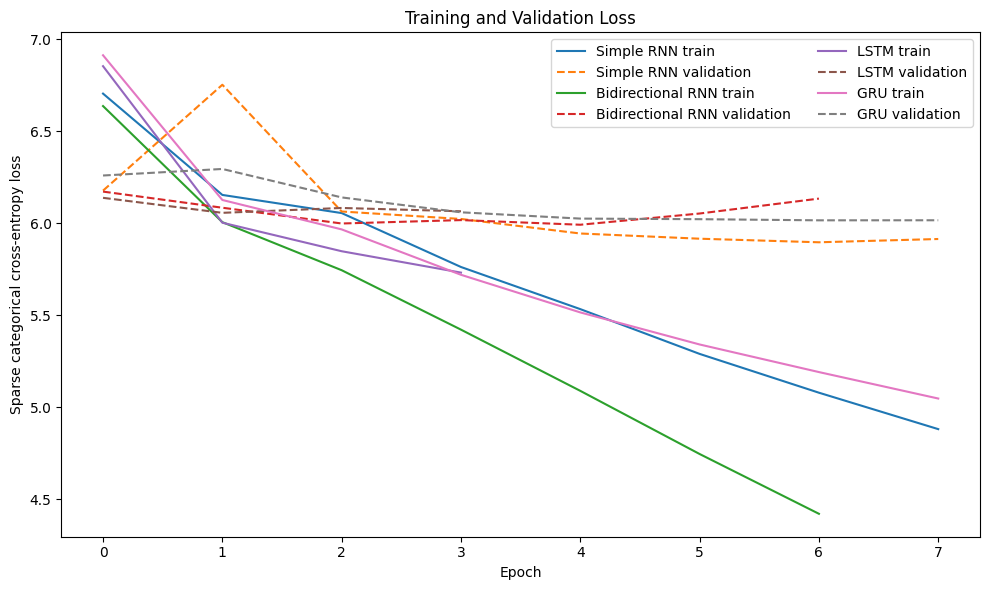

In [6]:
plt.figure(figsize=(10, 6))
for kind, hist in histories.items():
    plt.plot(hist.history["loss"], label=f"{kind} train")
    plt.plot(hist.history["val_loss"], linestyle="--", label=f"{kind} validation")
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy loss")
plt.title("Training and Validation Loss")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig("training_validation_loss.png", dpi=160)
plt.show()


## 6. Generate text using temperature sampling


In [11]:
def sample_next_word(probabilities, temperature=1.0):
    probs = np.asarray(probabilities, dtype=np.float64)
    probs = np.maximum(probs, 1e-12)
    logits = np.log(probs) / temperature
    logits -= np.max(logits)
    scaled = np.exp(logits)
    scaled /= scaled.sum()
    return int(np.random.choice(len(scaled), p=scaled))

def generate_text(model, seed_text, temperature=1.0, num_words=60):
    seed_tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]", seed_text.lower())
    context = [word_to_id.get(w, word_to_id["<unk>"]) for w in seed_tokens]
    if not context:
        context = [word_to_id.get("the", 1)]
    generated = list(seed_tokens)
    for _ in range(num_words):
        padded = ([word_to_id["<pad>"]] * max(0, SEQ_LEN-len(context)) + context[-SEQ_LEN:])
        x = np.array([padded[-SEQ_LEN:]], dtype=np.int32)
        probs = model.predict(x, verbose=0)[0]
        next_id = sample_next_word(probs, temperature)
        next_word = id_to_word.get(next_id, "<unk>")
        generated.append(next_word)
        context.append(next_id)
    # Simple detokenization for readable output.
    output = " ".join(generated)
    output = re.sub(r"\s+([.,!?;:])", r"\1", output)
    output = output.replace(" ' ", "'")
    return output

seed_sequences = [
    "the time traveller",
    "the machine was",
    "i saw the"
]
temperatures = [0.5, 1.0, 1.5]

samples = []
for kind, model in trained_models.items():
    for seed in seed_sequences:
        for temp in temperatures:
            sample = generate_text(model, seed, temperature=temp, num_words=60)
            samples.append({"Model": kind, "Seed": seed, "Temperature": temp, "Generated Text": sample})
            print(f"\\nMODEL={kind} | SEED='{seed}' | TEMPERATURE={temp}\\n{sample}\\n")

samples_df = pd.DataFrame(samples)
samples_df.to_csv("generated_text_samples.csv", index=False)


\nMODEL=Simple RNN | SEED='the time traveller' | TEMPERATURE=0.5\nthe time traveller. i was not down with the time of the white, and was, that the sphinx of the little of the time. “ and in the hands, “ i had, and the longer of the favourite, and the palace of the turning of my psychologist. the reaction of the editor. “ i\n
\nMODEL=Simple RNN | SEED='the time traveller' | TEMPERATURE=1.0\nthe time traveller ’ s time my was? and his editor of first, clearly long than is devoted, i seemed lit, there prepared enough to the delicately at the! out in upon body of me. of my serenity hitherto way i slower with rather mace, it i felt there against constant few if that now,\n
\nMODEL=Simple RNN | SEED='the time traveller' | TEMPERATURE=1.5\nthe time traveller with which towards the sky of crowded clearly did then perhaps they turned hitherto the had new to as that ways its journey he welcome as. faint you looked absolutely defeated steadily subterranean meek some hair mere tables made onset re

## 7. Quantitative and qualitative comparison


In [12]:
# Simple diversity/repetition indicators for generated samples.
def lexical_diversity(text):
    ws = re.findall(r"\b\w+\b", text.lower())
    return len(set(ws)) / max(1, len(ws))

def repeated_bigram_ratio(text):
    ws = re.findall(r"\b\w+\b", text.lower())
    bigrams = list(zip(ws, ws[1:]))
    if not bigrams:
        return 0.0
    return 1 - len(set(bigrams)) / len(bigrams)

samples_df["Lexical Diversity"] = samples_df["Generated Text"].apply(lexical_diversity)
samples_df["Repeated Bigram Ratio"] = samples_df["Generated Text"].apply(repeated_bigram_ratio)
qual_summary = samples_df.groupby(["Model", "Temperature"])[
    ["Lexical Diversity", "Repeated Bigram Ratio"]
].mean().reset_index()
display(qual_summary)
qual_summary.to_csv("qualitative_generation_metrics.csv", index=False)

print("Interpretation guide:")
print("- Lower validation loss/perplexity generally indicates better next-word prediction.")
print("- Lower temperature usually makes sampling more conservative and can increase repetition.")
print("- Higher temperature usually increases variety but may reduce coherence.")
print("- Use the saved samples to manually judge grammaticality, contextual consistency, diversity, and repetition.")


,Model,Temperature,Lexical Diversity,Repeated Bigram Ratio
0,Bidirectional RNN,0.5,0.460940,0.205194
1,Bidirectional RNN,1.0,0.834269,0.012350
2,Bidirectional RNN,1.5,0.943974,0.000000
3,GRU,0.5,0.450337,0.199319
4,GRU,1.0,0.774397,0.012346
5,GRU,1.5,0.887060,0.000000
6,LSTM,0.5,0.503543,0.072160
7,LSTM,1.0,0.793483,0.000000
8,LSTM,1.5,0.955217,0.000000
9,Simple RNN,0.5,0.471575,0.187949


Interpretation guide:
- Lower validation loss/perplexity generally indicates better next-word prediction.
- Lower temperature usually makes sampling more conservative and can increase repetition.
- Higher temperature usually increases variety but may reduce coherence.
- Use the saved samples to manually judge grammaticality, contextual consistency, diversity, and repetition.


## 8. Conclusion template — complete using your actual output

Use your measured `results_df`, generated samples, and `qual_summary` to fill in this section. Do not assume one model is best before observing the results.

- **Best quantitative model:** identify the model with the lowest validation loss/perplexity, while also considering accuracy and training time.
- **Best qualitative model:** identify which model produces the most coherent and contextually consistent text with reasonable diversity and limited repetition.
- **Temperature effect:** compare 0.5, 1.0, and 1.5 using the same seed sequences. Describe the observed changes in coherence, diversity, and repetition.
- **Overall conclusion:** justify the best trade-off for this dataset using your actual metrics and examples.

## Files generated by this notebook

- `model_comparison_results.csv`
- `training_validation_loss.png`
- `generated_text_samples.csv`
- `qualitative_generation_metrics.csv`
- `the_time_machine.txt`


In [13]:
print("Number of generated samples:", len(samples_df))

for _, row in samples_df.head(6).iterrows():
    print("\nModel:", row["Model"])
    print("Temperature:", row["Temperature"])
    print("Generated text:", row["Generated Text"])
    print("-" * 60)

Number of generated samples: 36

Model: Simple RNN
Temperature: 0.5
Generated text: the time traveller. i was not down with the time of the white, and was, that the sphinx of the little of the time. “ and in the hands, “ i had, and the longer of the favourite, and the palace of the turning of my psychologist. the reaction of the editor. “ i
------------------------------------------------------------

Model: Simple RNN
Temperature: 1.0
Generated text: the time traveller ’ s time my was? and his editor of first, clearly long than is devoted, i seemed lit, there prepared enough to the delicately at the! out in upon body of me. of my serenity hitherto way i slower with rather mace, it i felt there against constant few if that now,
------------------------------------------------------------

Model: Simple RNN
Temperature: 1.5
Generated text: the time traveller with which towards the sky of crowded clearly did then perhaps they turned hitherto the had new to as that ways its journey he wel

In [14]:
display(
    results_df.sort_values("Validation Loss")[
        ["Model", "Validation Loss", "Perplexity",
         "Validation Accuracy", "Training Time (seconds)"]
    ]
)

,Model,Validation Loss,Perplexity,Validation Accuracy,Training Time (seconds)
0,Simple RNN,5.896249,363.670884,0.126176,50.168966
1,Bidirectional RNN,5.991584,400.047904,0.125392,69.547988
3,GRU,6.015560,409.755299,0.136364,77.233221
2,LSTM,6.056230,426.763531,0.101097,38.799093


In [15]:
import os
import zipfile
from google.colab import files

outputs = [
    "model_comparison_results.csv",
    "training_validation_loss.png",
    "generated_text_samples.csv",
    "qualitative_generation_metrics.csv",
    "the_time_machine.txt"
]

with zipfile.ZipFile("assignment_results.zip", "w") as z:
    for name in outputs:
        if os.path.exists(name):
            z.write(name)
            print("Included:", name)
        else:
            print("Missing:", name)

files.download("assignment_results.zip")

Included: model_comparison_results.csv
Included: training_validation_loss.png
Included: generated_text_samples.csv
Included: qualitative_generation_metrics.csv
Included: the_time_machine.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>